# Лабораторная работа № 1. Первичный анализ SMS Spam Collection

## Основные результаты

Исходный файл содержит **5 574 сообщения**: **4 827 ham (86,60%)** и **747 spam (13,40%)**.
Отношение численности классов — **6,46 : 1**. Обнаружено **403 избыточные повторные записи**;
исходный файл оставлен без изменений. Пропуски, пустые сообщения и конфликтующие метки
одинаковых текстов отсутствуют. Эти выводы проверяются вычислениями ниже.

Перед загрузкой выполняется проверка SHA256 архива, основного файла и описания.
Изменение одного байта проверяется на временной копии. Наличие корректного хэша
не подтверждает правильность меток и достоверность первичного источника.

## Задача и методика

Направление — NLP. Планируемая задача — бинарная классификация англоязычных SMS:
на вход поступает текст, на выходе возвращаются класс `ham` / `spam` и, после обучения
и отдельной проверки, оценка принадлежности к классу. Потенциальный пользователь —
разработчик фильтра сообщений, вызывающий локальную функцию или будущий API.

В этой работе модель не обучается. В следующих работах исходной моделью может быть
TF–IDF с логистической регрессией. Признаки и классификатор следует обучать только на
обучающей выборке.

### Предпосылки и ограничения

- Единица наблюдения — одна строка исходного файла: метка и текст, разделённые первой табуляцией.
- Кавычки внутри SMS не интерпретируются как синтаксис CSV; строки не отбрасываются.
- Дубликаты подсчитываются до любых преобразований и не удаляются из исходного файла.
- Нормализация NFKC, casefold и пробельных символов используется только для поиска групп похожих записей.
- Старый учебный корпус не отражает все современные схемы спама и не подтверждает применимость к русскому языку.

## Окружение и проверка целостности

In [1]:
from pathlib import Path
import sys, json, platform, getpass

candidates = [Path.cwd(), Path.cwd().parent]
ROOT = next((p for p in candidates if (p / "security/dataset-manifest.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Откройте notebook из каталога проекта или notebooks/")
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.integrity import default_baseline, read_manifest, verify_dataset
from src.dataset import load_dataset, profile_dataset, normalize_for_grouping

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 120, "savefig.dpi": 180,
})
COLORS = {"ham": "#245A81", "spam": "#C58A19"}
print(f"Python {platform.python_version()}; pandas {pd.__version__}; пользователь {getpass.getuser()}")
print("Эталон:", default_baseline())
for name, digest in verify_dataset().items():
    print(f"OK {digest}  {name}")

Python 3.12.3; pandas 3.1.0; пользователь mluser
Эталон: /var/lib/ml-lab/integrity/dataset-manifest.json
OK 7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d  data/raw/SMSSpamCollection
OK 1587ea43e58e82b14ff1f5425c88e17f8496bfcdb67a583dbff9eefaf9963ce3  data/raw/sms_spam_collection.zip
OK 8753cd2d3cab68f80c8257851b8c2037778c267f55accb6fd1b5a2e32d36a84e  data/raw/readme


## Данные

Источник: [UCI SMS Spam Collection](https://archive.ics.uci.edu/dataset/228/sms+spam+collection).
DOI: [10.24432/C5CC84](https://doi.org/10.24432/C5CC84).
Авторы: Tiago Almeida и José María Gómez Hidalgo (2011).
Лицензия, указанная UCI: CC BY 4.0. Архив — 203 415 байт, основной файл — 477 907 байт.
В таблице один исходный признак `text` и одна целевая переменная `target` с двумя классами.

In [2]:
df = load_dataset()
profile = profile_dataset(df)
assert profile["records"] == 5574
assert profile["classes"] == {"ham": 4827, "spam": 747}
summary = pd.DataFrame({
    "Показатель": ["Объекты", "Исходные текстовые признаки", "Классы", "Пропущенные значения", "Пустые тексты", "Избыточные дубликаты строк", "Уникальные строки", "Конфликты меток одинаковых текстов"],
    "Значение": [len(df), 1, df["target"].nunique(), profile["missing_cells"], profile["empty_texts"], profile["duplicate_rows_excess"], profile["unique_rows"], profile["exact_text_label_conflicts"]]
})
display(summary)
(ROOT / "evidence").mkdir(exist_ok=True)
(ROOT / "evidence/dataset-profile.json").write_text(json.dumps(profile, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

,Показатель,Значение
0,Объекты,5574
1,Исходные текстовые признаки,1
2,Классы,2
3,Пропущенные значения,0
4,Пустые тексты,0
5,Избыточные дубликаты строк,403
6,Уникальные строки,5171
7,Конфликты меток одинаковых текстов,0


1015

## Распределение классов

,Класс,Количество SMS,"Доля, %"
0,ham,4827,86.6
1,spam,747,13.4


Отношение большего класса к меньшему: 6.4618 : 1
Accuracy константного классификатора ham: 86.5985%


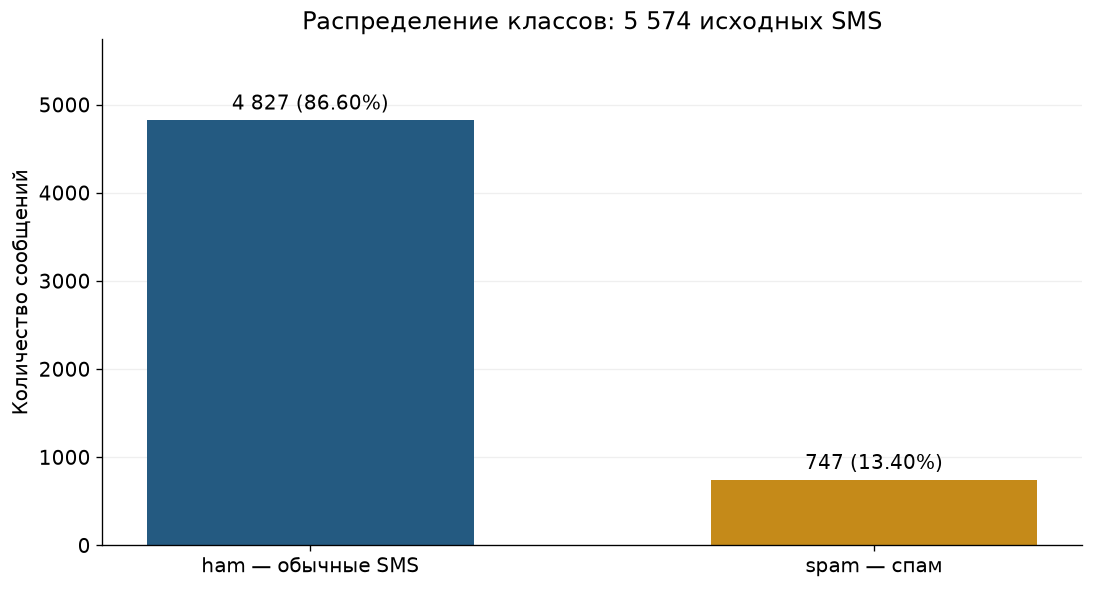

In [3]:
counts = df["target"].value_counts().reindex(["ham", "spam"])
shares = counts / counts.sum() * 100
distribution = pd.DataFrame({"Класс": counts.index, "Количество SMS": counts.values, "Доля, %": shares.round(2).values})
display(distribution)
print(f"Отношение большего класса к меньшему: {counts.max() / counts.min():.4f} : 1")
print(f"Accuracy константного классификатора ham: {counts.max() / len(df):.4%}")

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
bars = ax.bar(["ham — обычные SMS", "spam — спам"], counts.values, color=[COLORS[c] for c in counts.index], width=0.58)
ax.set(title=f"Распределение классов: {len(df):,} исходных SMS".replace(",", " "), ylabel="Количество сообщений")
ax.set_ylim(0, counts.max() * 1.19)
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
for bar, count, share in zip(bars, counts.values, shares.values):
    ax.text(bar.get_x() + bar.get_width()/2, count + 65, f"{count:,} ({share:.2f}%)".replace(",", " "), ha="center", va="bottom")
(ROOT / "figures").mkdir(exist_ok=True)
fig.savefig(ROOT / "figures/class_distribution.png")
plt.show()

Датасет несбалансирован: обычных сообщений в 6,46 раза больше, чем спама.
Предсказание `ham` для всех объектов даёт accuracy 86,60% при нулевой полноте класса `spam`.
Поэтому при обучении следует оценивать precision, recall и F1 для `spam`, macro-F1,
balanced accuracy и матрицу ошибок. Это рекомендации для следующих работ; качество модели
на этом этапе не измерялось. Искусственное выравнивание классов не выполнялось.

## Дубликаты и риск утечки между выборками

In [4]:
normalized = df["text"].map(normalize_for_grouping)
duplicate_summary = pd.DataFrame({
    "Проверка": ["Повторные строки сверх первого вхождения", "Повторные нормализованные тексты сверх первого вхождения", "Конфликты меток нормализованных текстов"],
    "Количество": [profile["duplicate_rows_excess"], profile["normalized_duplicate_texts_excess"], profile["normalized_text_label_conflicts"]]
})
display(duplicate_summary)
print("Исходные данные не изменялись. Уникальных строк:", len(df.drop_duplicates()))

,Проверка,Количество
0,Повторные строки сверх первого вхождения,403
1,Повторные нормализованные тексты сверх первого...,415
2,Конфликты меток нормализованных текстов,0


Исходные данные не изменялись. Уникальных строк: 5171


При случайном разделении отдельных строк один и тот же текст может оказаться в обучении
и тесте. Это создаёт утечку и может завысить оценку качества. В следующих работах
следует разделять группы нормализованных текстов с сохранением долей классов,
например через StratifiedGroupKFold, и проверять отсутствие пересечения групп.
Нормализация выявила 415 повторных нормализованных текстов сверх первого вхождения.

## Длина текстов

,SMS,"Минимум, символов","Медиана, символов","Среднее, символов","Максимум, символов"
target,,,,,
ham,4827,2,52.0,71.47,910
spam,747,13,149.0,138.68,223


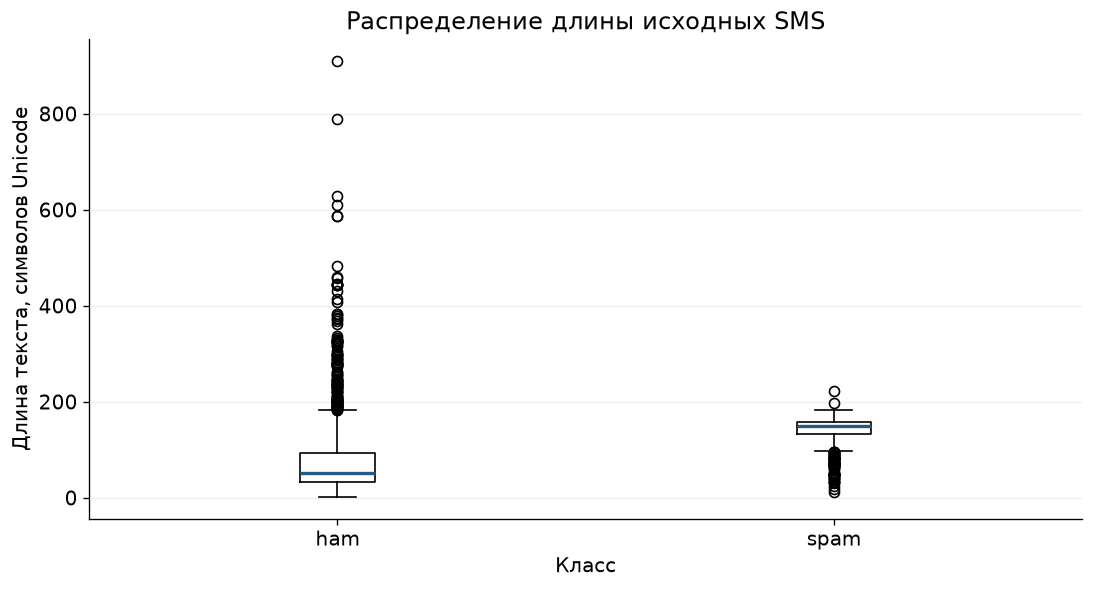

In [5]:
lengths = df.assign(characters=df["text"].str.len())
length_summary = lengths.groupby("target")["characters"].agg(["count", "min", "median", "mean", "max"]).round(2)
length_summary.columns = ["SMS", "Минимум, символов", "Медиана, символов", "Среднее, символов", "Максимум, символов"]
display(length_summary)

fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
ax.boxplot([lengths.loc[lengths["target"].eq(c), "characters"] for c in ["ham", "spam"]], tick_labels=["ham", "spam"], showfliers=True, medianprops={"color": "#245A81", "linewidth": 2})
ax.set(title="Распределение длины исходных SMS", xlabel="Класс", ylabel="Длина текста, символов Unicode")
ax.grid(axis="y", alpha=0.2)
fig.savefig(ROOT / "figures/text_lengths.png")
plt.show()

Длина измеряется числом символов Unicode, а не размером файла и не числом токенов.
Выбросы показаны; сообщения не обрезались и не удалялись. Различие длины классов
само по себе не доказывает причинную связь и не гарантирует качество классификации.

## Проверка обнаружения изменения данных

In [6]:
import subprocess
result = subprocess.run([sys.executable, str(ROOT / "scripts/tamper_demo.py")], cwd=ROOT, capture_output=True, text=True, check=True)
print(result.stdout)
assert verify_dataset()
print("Повторная проверка исходных файлов: OK")

PASS: изменение одного байта временной копии обнаружено.
PASS: оригинальный датасет и эталон сохранены без изменений.

Повторная проверка исходных файлов: OK


## Выводы

Корпус пригоден для учебной бинарной классификации SMS и последующих экспериментов
с отравлением данных, искажением входного текста и контролем целостности.
Основные ограничения — дисбаланс классов, повторные тексты, возраст корпуса и англоязычные данные.
Сохранённый эталон SHA256 позволяет обнаружить изменение файлов относительно выбранного снимка.
На виртуальной машине эталон следует хранить вне проекта, в каталоге root,
а проверку выполнять перед анализом и обучением. Отдельная проверка источника и качества разметки
остаётся необходимой.

Настройка SSH, UFW и обновлений подтверждается выводом команд именно целевой VM
в `evidence/vm/`; выполнение этого notebook не подтверждает настройку этих служб.